In [1]:
# First, we import our libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [2]:
#import file

titanic_data = pd.read_csv('data/titanic.csv')
titanic_data.head()

,Survived,Pclass,Name,Sex,Age,SibSp,PaCh,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500


In [3]:
titanic_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  887 non-null    int64  
 1   Pclass    887 non-null    int64  
 2   Name      887 non-null    object 
 3   Sex       887 non-null    object 
 4   Age       887 non-null    float64
 5   SibSp     887 non-null    int64  
 6   PaCh      887 non-null    int64  
 7   Fare      887 non-null    float64
dtypes: float64(2), int64(4), object(2)
memory usage: 55.6+ KB


In [4]:
titanic_data.describe()

,Survived,Pclass,Age,SibSp,PaCh,Fare
count,887.000000,887.000000,887.000000,887.000000,887.000000,887.00000
mean,0.385569,2.305524,29.471443,0.525366,0.383315,32.30542
std,0.487004,0.836662,14.121908,1.104669,0.807466,49.78204
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.00000
25%,0.000000,2.000000,20.250000,0.000000,0.000000,7.92500
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.45420
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.13750
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.32920


In [5]:
titanic_data["Survived"].value_counts()

Survived
0    545
1    342
Name: count, dtype: int64

In [6]:
titanic_data.isnull().sum()

Survived    0
Pclass      0
Name        0
Sex         0
Age         0
SibSp       0
PaCh        0
Fare        0
dtype: int64

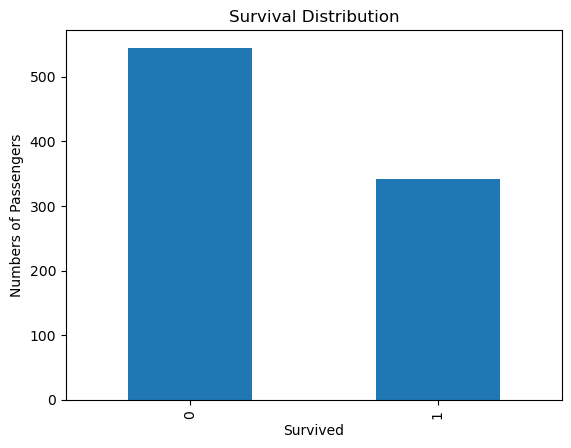

In [7]:
titanic_data["Survived"].value_counts().plot(kind="bar")
plt.title("Survival Distribution")
plt.xlabel("Survived")
plt.ylabel("Numbers of Passengers")

plt.show()

In [8]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'PaCh', 'Fare']

target = 'Survived'

x = titanic_data[features].copy()
y = titanic_data[target].copy()

In [9]:
titanic_data.columns

Index(['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'PaCh', 'Fare'], dtype='object')

In [10]:
x.head() 

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,male,22.0,1,0,7.2500
1,1,female,38.0,1,0,71.2833
2,3,female,26.0,0,0,7.9250
3,1,female,35.0,1,0,53.1000
4,3,male,35.0,0,0,8.0500


In [11]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [12]:
x['Sex'] = x['Sex'].apply(lambda x: 1 if x == 'female' else 0)

In [13]:
x.head()

,Pclass,Sex,Age,SibSp,PaCh,Fare
0,3,0,22.0,1,0,7.2500
1,1,1,38.0,1,0,71.2833
2,3,1,26.0,0,0,7.9250
3,1,1,35.0,1,0,53.1000
4,3,0,35.0,0,0,8.0500


In [14]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [15]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (709, 6)
Testing data: (178, 6)


In [16]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [18]:
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(x_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [21]:
logistic_prediction = logistic_model.predict(x_test)
logistic_accuracy = accuracy_score(y_test, logistic_prediction)

print('Logistic Regression Accuracy:', logistic_accuracy)

Logistic Regression Accuracy: 0.6348314606741573


C:\Users\adeol\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [23]:
print(classification_report(y_test, logistic_prediction))

              precision    recall  f1-score   support

           0       0.64      0.94      0.76       109
           1       0.62      0.14      0.24        69

    accuracy                           0.63       178
   macro avg       0.63      0.54      0.50       178
weighted avg       0.63      0.63      0.56       178



In [24]:
# Train Decision Tree  
tree_model = DecisionTreeClassifier(
    max_depth=3,    
    random_state=42
)

tree_model.fit(x_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


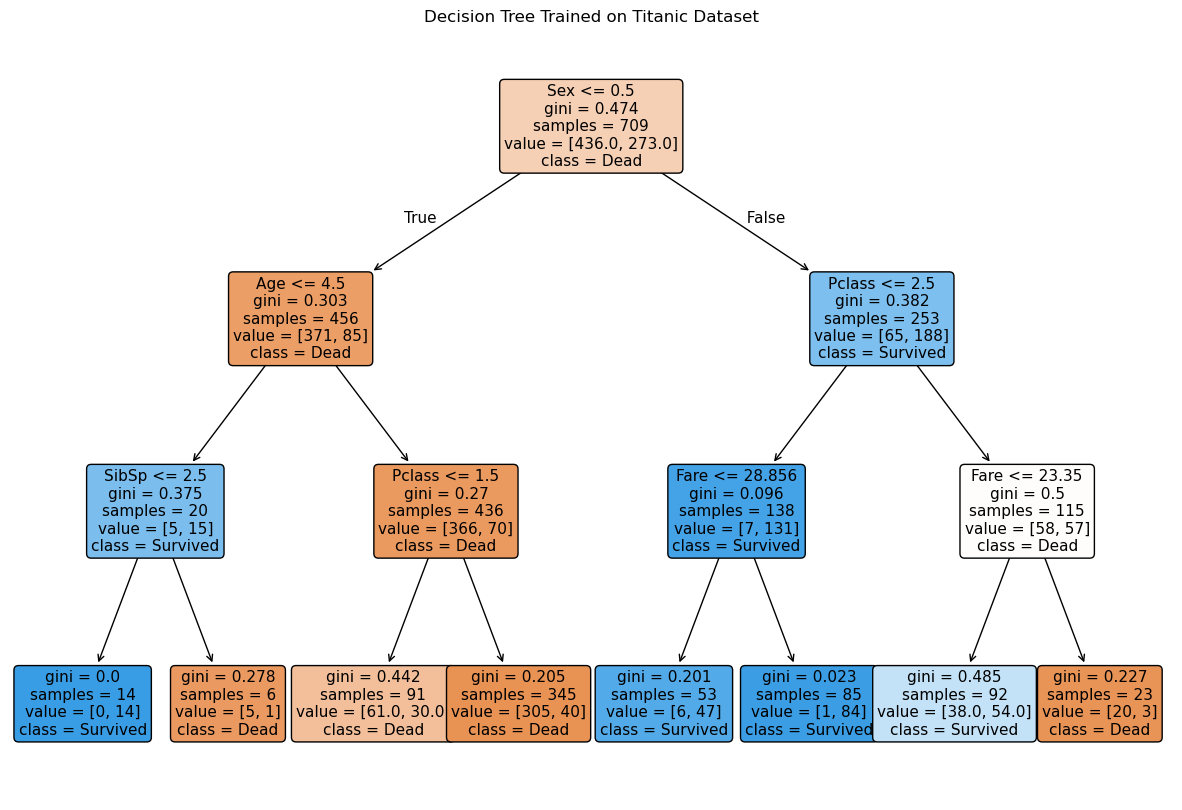

In [25]:
plt.figure(figsize=(15,10))

plot_tree(
    tree_model,
    feature_names=features,
    class_names=["Dead", "Survived"],
    filled=True,
    rounded=True,
    fontsize=11
)

plt.title('Decision Tree Trained on Titanic Dataset')
plt.show()

In [27]:
#Train Decision Tree

tree_prediction = tree_model.predict(x_test)
tree_accuracy = accuracy_score(y_test, tree_prediction)

print('Tree Decision Accuracy:', tree_accuracy)

Tree Decision Accuracy: 0.8033707865168539


In [29]:
print(classification_report(y_test, tree_prediction))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       109
           1       0.79      0.67      0.72        69

    accuracy                           0.80       178
   macro avg       0.80      0.78      0.79       178
weighted avg       0.80      0.80      0.80       178



In [34]:
# Train RandomForest Classifier

forest_model = RandomForestClassifier(max_depth=3, n_estimators=100, random_state=42)

forest_model.fit(x_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [37]:
forest_prediction = forest_model.predict(x_test)
forest_accuracy =  accuracy_score(y_test, forest_prediction)

print('Random Forest Accuracy:', forest_accuracy)

Random Forest Accuracy: 0.8089887640449438


In [38]:
print(classification_report(y_test, forest_prediction))

              precision    recall  f1-score   support

           0       0.82      0.89      0.85       109
           1       0.80      0.68      0.73        69

    accuracy                           0.81       178
   macro avg       0.81      0.79      0.79       178
weighted avg       0.81      0.81      0.81       178



In [39]:
# Let's compare out Models

results = pd.DataFrame({
"Model": [
"Logistic Regression",
"Decision Tree",
"Random Forest"
],
"Accuracy": [
logistic_accuracy,
tree_accuracy,
forest_accuracy
    ]
})
results

,Model,Accuracy
0,Logistic Regression,0.634831
1,Decision Tree,0.803371
2,Random Forest,0.808989


In [44]:
results['Accuracy'] = results['Accuracy']*100
results['Accuracy'] = results['Accuracy'].round(2)

In [46]:
results.sort_values(by='Accuracy', ascending=False)

,Model,Accuracy
2,Random Forest,8090.0
1,Decision Tree,8034.0
0,Logistic Regression,6348.0


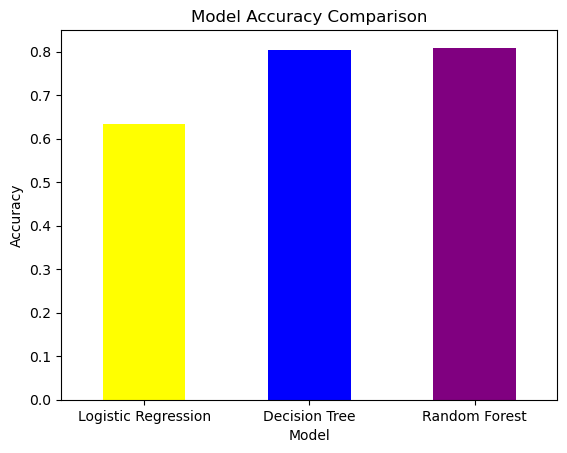

In [40]:
colors= ['Yellow', 'Blue', 'Purple']
results.plot(
x="Model",
y="Accuracy",
kind="bar",
color=colors,
legend=False
)
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.show()